In [3]:
import numpy as np
from scipy import signal as sig
import matplotlib.pyplot as plt
%config InlineBackend.figure_format = 'svg'
import Funciones as Funciones
from NNMF_GIF import NNMF_GIF 
from pathlib import Path
from ipyfilechooser import FileChooser
import ipywidgets as widgets
import NNMF_GIF2 as CONMF
import NNMF_GIF as NMF

In [4]:
FC = FileChooser('Señales AC3E/Femenino')
FC.layout = widgets.Layout(width='1000px')
display(FC)

FileChooser(path='G:\Mi unidad\Facultad\Beca CIN\NNMF-GIF\Señales AC3E\Femenino', filename='', title='', show_…

In [11]:
archivo = Path(FC.selected)
nombre_archivo = archivo.name
datos = np.loadtxt(archivo, delimiter='\t', skiprows=1)

orden = 10 
ripple = 0.1
fc     = 1100
fs_r = 8000
to = 0
tf = 50

tiempos       = np.arange(to,tf,1000/fs_r)
alfa = 0.96
alfa_grid = 0.3


señal_OVV_  = datos[:, 2] - np.mean(datos[:, 2])
b,a   = sig.cheby1(orden,ripple,fc,'lowpass',fs=fs_r)
señal_OVV_f = sig.filtfilt(b,a,señal_OVV_)


flujo_OVV_original =  sig.lfilter([1],[1,-alfa],señal_OVV_f)
flujo_OVV_original = Funciones.Detrend(tiempos,flujo_OVV_original)
flujo_OVV_original = flujo_OVV_original+abs(min(flujo_OVV_original))
flujo_OVV_original = flujo_OVV_original/max(abs(flujo_OVV_original))


# FN01_A_11 -> F=725, Q =3.1
b, a = sig.iirnotch(w0=725,fs=fs_r, Q=3.1)
w_notch, h_notch = sig.freqz(a,b,fs=fs_r)
flujo_ovv_notch  = sig.lfilter(b, a, flujo_OVV_original)


fft_flujo_OVV_original, frec_flujo_OVV_original= Funciones.FFT(flujo_OVV_original, fs_r)
flujo_ovv_lpc,w_lpc,h_lpc,polos,polos_filtrados, ceros,a_filtrado = Funciones.LPC(señal=flujo_OVV_original,orden=3)
w_lpc_,h_lpc_ = sig.freqz([1],a_filtrado,fs=fs_r)


color_notch = 'green'
color_lpc  = 'orange'
color_flujo = 'k'
color1 = 'red'
color2 = 'blue'

# Definición de parámetros
norma ='frobenius'
pre_iteraciones = 0
iteraciones     = 250
p_filtro        = 12
alfa = 0.96
p = 0.55
pre_enfasis     = True
duracion        = 5.5
guardar_proceso = False
fs_r = 8000
# Modelo
señal_OVV_f__ =  sig.lfilter([1, 0], [1], señal_OVV_f)
SP1 = NNMF_GIF(
    señal_OVV_f__, 
    tiempos,fs_r,
    pre_enfasis=True,
    p_filtro=2,
    p=1,alfa=0.90)
fw1,hw1 = sig.freqz([1],SP1.a_W1,fs=fs_r)
fw2,hw2 = sig.freqz([1],SP1.a_W2,fs=fs_r)

flujo_OVV_w1 = Funciones.Detrend(SP1.tiempos_gve,SP1.flujo1)
flujo_OVV_w1 = flujo_OVV_w1+abs(min(flujo_OVV_w1))
flujo_OVV_w1 = flujo_OVV_w1/max(abs(flujo_OVV_w1))

flujo_OVV_w2 = Funciones.Detrend(SP1.tiempos_gve,SP1.flujo2)
flujo_OVV_w2 = flujo_OVV_w2+abs(min(flujo_OVV_w2))
flujo_OVV_w2 = flujo_OVV_w2/max(abs(flujo_OVV_w2))


mask = (tiempos >= 5.0) & (tiempos <= 45.0)
flujo_ovv_lpc = Funciones.Detrend(tiempos[mask],flujo_ovv_lpc[mask])
flujo_ovv_lpc = flujo_ovv_lpc+abs(min(flujo_ovv_lpc))
flujo_ovv_lpc = flujo_ovv_lpc/max(abs(flujo_ovv_lpc))



flujo_ovv_notch = Funciones.Detrend(tiempos,flujo_ovv_notch)
flujo_ovv_notch = flujo_ovv_notch+abs(min(flujo_ovv_notch))
flujo_ovv_notch = flujo_ovv_notch/max(abs(flujo_ovv_notch))

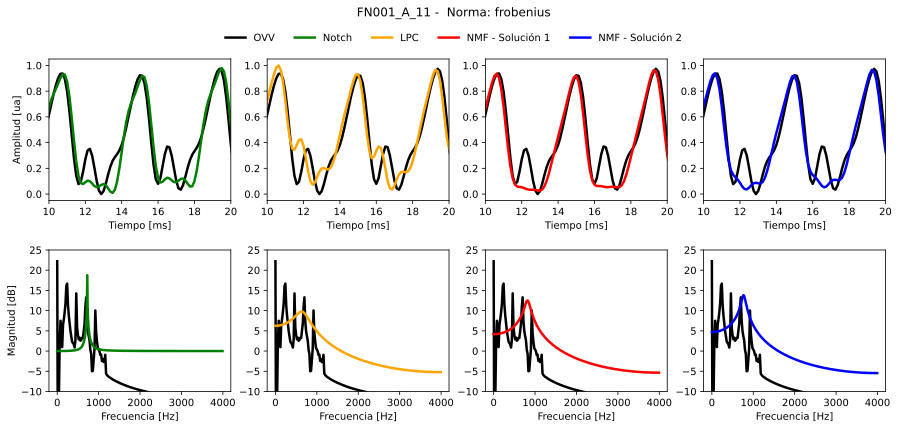

In [12]:
fig,ax = plt.subplots(2,4,figsize=(15,6))
plt.subplots_adjust(hspace=0.35)
lw = 2.5
for j in range(0,4):
    ax[0][j].plot(tiempos, flujo_OVV_original, color='k',linewidth=lw)
    ax[0][j].set_xlim([10,20])
    ax[1][j].plot(frec_flujo_OVV_original, 10*np.log10(abs(fft_flujo_OVV_original)), color='k',linewidth=lw)
    ax[1][j].set_ylim([-10,25])
    ax[1][j].set_xlabel('Frecuencia [Hz]')

ax[0][0].plot(tiempos, flujo_ovv_notch, color=color_notch,linewidth=lw)
ax[0][0].set_xlabel('Tiempo [ms]')
ax[0][0].set_ylabel("Amplitud [ua]")
ax[1][0].plot(w_notch, 10*np.log10(abs(h_notch)), color=color_notch,linewidth=lw)
ax[1][0].set_ylabel('Magnitud [dB]')

ax[0][1].plot(tiempos[mask], flujo_ovv_lpc, color=color_lpc,linewidth=lw)
ax[0][1].set_xlabel('Tiempo [ms]')
ax[1][1].plot(w_lpc_, 10*np.log10(abs(h_lpc_)), color=color_lpc,label='LPC',linewidth=lw)


ax[0][2].plot(SP1.tiempos_gve,flujo_OVV_w1, color=color1,linewidth=lw)
ax[0][2].set_xlabel('Tiempo [ms]')
ax[1][2].plot(fw1, 10*np.log10(abs(hw1)), color=color1,linewidth=lw)

ax[0][3].plot(SP1.tiempos_gve,flujo_OVV_w2, color=color2,linewidth=lw)
ax[0][3].set_xlabel('Tiempo [ms]')
ax[1][3].plot(fw2, 10*np.log10(abs(hw2)), color=color2,linewidth=lw)

handles = [
    plt.Line2D([0], [0], color='k', alpha=1, label='OVV',linewidth=lw),
    plt.Line2D([0], [0], color=color_notch, label='Notch',linewidth=lw),
    plt.Line2D([0], [0], color=color_lpc, label='LPC',linewidth=lw),
    plt.Line2D([0], [0], color=color1, label='NMF - Solución 1',linewidth=lw),
    plt.Line2D([0], [0], color=color2, label='NMF - Solución 2',linewidth=lw),

]
'''
fig.legend(handles=handles,
           loc='upper center',
           ncol=3,
           frameon=True,
           fontsize=11,
           bbox_to_anchor=(0.5,0.96));
'''
titulo = nombre_archivo.split(".txt")[0] + " -  Norma: " + norma 

fig.suptitle(titulo,
             fontsize=12,
             x=0.5,y=1)

fig.legend(handles=handles,
           loc='upper center',
           bbox_to_anchor=(0.5, 0.96),  # ← misma altura, más a la derecha
           ncol=5,
           frameon=False);

fig.savefig('NMF_OVV.pdf',bbox_inches = 'tight');